In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [4]:
converted = pd.to_numeric(df['TotalCharges'], errors='coerce') # نحاول نحوّل العمود لأرقام، واللي مش هيتحول هيبقى NaN
# نشوف الصفوف اللي فشلت
df[converted.isna()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


#عندنا missing value total chareges عندنا حلين نعمل drop او نملي zeros


In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
# نتأكد
print(df['TotalCharges'].dtype)
print(df['TotalCharges'].isna().sum())

float64
0


In [6]:
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


الهدف من الـ EDA: نفهم مين بيمشي وليه قبل ما نبني أي model. الـ insights دي هي اللي هتتكلم عنها في الإنترفيو، مش الكود.

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

In [9]:
tenure_group = pd.cut(df['tenure'], bins=[0, 12, 24, 48, 72], include_lowest=True)

pd.crosstab(tenure_group, df['Churn'], normalize='index') * 100

Churn,No,Yes
tenure,,
"(-0.001, 12.0]",52.561757,47.438243
"(12.0, 24.0]",71.289062,28.710938
"(24.0, 48.0]",79.611041,20.388959
"(48.0, 72.0]",90.486824,9.513176


In [10]:
pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


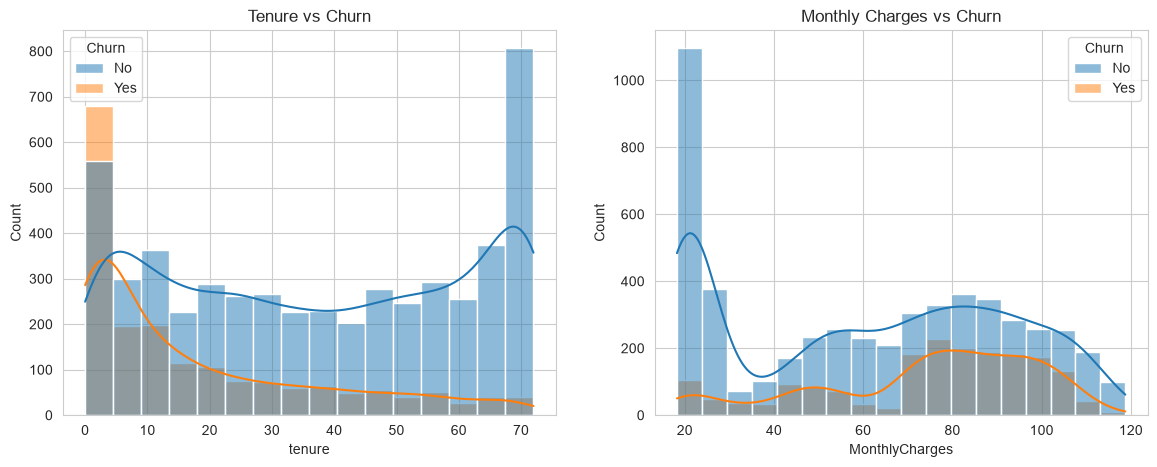

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='tenure', hue='Churn', kde=True, ax=axes[0])
axes[0].set_title('Tenure vs Churn')

sns.histplot(data=df, x='MonthlyCharges', hue='Churn', kde=True, ax=axes[1])
axes[1].set_title('Monthly Charges vs Churn')

plt.show()

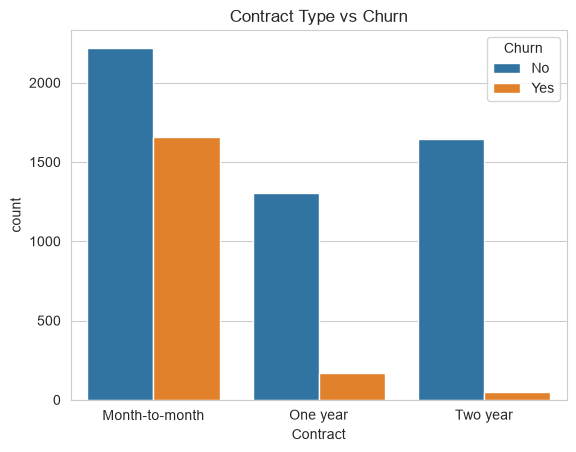

In [12]:
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Contract Type vs Churn')
plt.show()

In [13]:
cat_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
            'PhoneService', 'MultipleLines', 'InternetService',
            'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies',
            'Contract', 'PaperlessBilling', 'PaymentMethod']

for col in cat_cols:
    churn_rate = pd.crosstab(df[col], df['Churn'], normalize='index')['Yes'] * 100
    print(churn_rate.round(1))
    print('-' * 30)

gender
Female    26.9
Male      26.2
Name: Yes, dtype: float64
------------------------------
SeniorCitizen
0    23.6
1    41.7
Name: Yes, dtype: float64
------------------------------
Partner
No     33.0
Yes    19.7
Name: Yes, dtype: float64
------------------------------
Dependents
No     31.3
Yes    15.5
Name: Yes, dtype: float64
------------------------------
PhoneService
No     24.9
Yes    26.7
Name: Yes, dtype: float64
------------------------------
MultipleLines
No                  25.0
No phone service    24.9
Yes                 28.6
Name: Yes, dtype: float64
------------------------------
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Yes, dtype: float64
------------------------------
OnlineSecurity
No                     41.8
No internet service     7.4
Yes                    14.6
Name: Yes, dtype: float64
------------------------------
OnlineBackup
No                     39.9
No internet service     7.4
Yes                    21.5
Name: Ye

## Data Preparation

In [14]:
df = df.drop('customerID', axis=1)

In [15]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
print(df['Churn'].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [16]:
X = df.drop('Churn', axis=1)   # خد الجدول كله وامسح منه عمود Churn
y = df['Churn']                # خد عمود Churn لوحده

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print("Train churn %:", y_train.mean().round(3))
print("Test churn %:", y_test.mean().round(3))

(5634, 19) (1409, 19)
Train churn %: 0.265
Test churn %: 0.265


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print("Train churn %:", y_train.mean().round(3))
print("Test churn %:", y_test.mean().round(3))

(5634, 19) (1409, 19)
Train churn %: 0.265
Test churn %: 0.265


5: Encoding + Scaling

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

cat_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
            'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
            'PaperlessBilling', 'PaymentMethod']

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cat_cols)
], remainder='passthrough')

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print(X_train_prep.shape, X_test_prep.shape)

(5634, 40) (1409, 40)


## Modeling

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train_prep, y_train)
y_pred_dummy = dummy.predict(X_test_prep)

print("Accuracy:", round(accuracy_score(y_test, y_pred_dummy), 3))
print("Recall:  ", round(recall_score(y_test, y_pred_dummy), 3))
print("F1:      ", round(f1_score(y_test, y_pred_dummy), 3))

Accuracy: 0.735
Recall:   0.0
F1:       0.0


In [21]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_prep, y_train)
y_pred_lr = log_reg.predict(X_test_prep)

print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 3))
print("Recall:  ", round(recall_score(y_test, y_pred_lr), 3))
print("F1:      ", round(f1_score(y_test, y_pred_lr), 3))

Accuracy: 0.806
Recall:   0.559
F1:       0.604


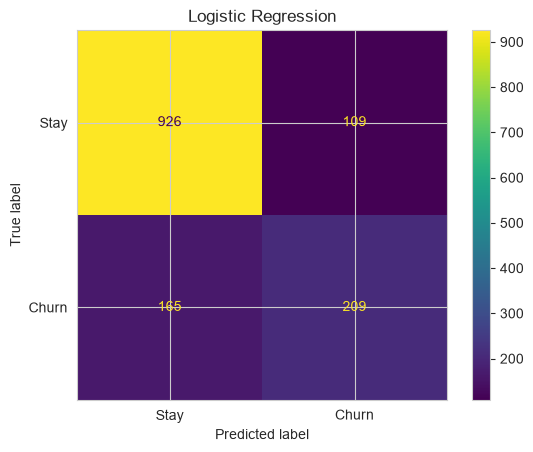

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, display_labels=['Stay', 'Churn'])
plt.title('Logistic Regression')
plt.show()

Accuracy: 0.738
Recall:   0.783
F1:       0.614


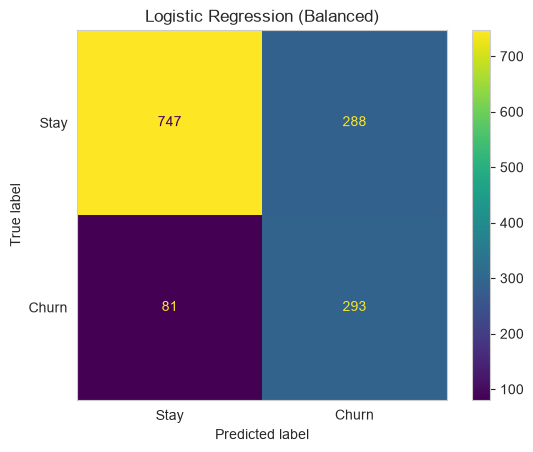

In [23]:
log_reg_bal = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
log_reg_bal.fit(X_train_prep, y_train)
y_pred_bal = log_reg_bal.predict(X_test_prep)

print("Accuracy:", round(accuracy_score(y_test, y_pred_bal), 3))
print("Recall:  ", round(recall_score(y_test, y_pred_bal), 3))
print("F1:      ", round(f1_score(y_test, y_pred_bal), 3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_bal, display_labels=['Stay', 'Churn'])
plt.title('Logistic Regression (Balanced)')
plt.grid(False)
plt.show()

In [24]:
from sklearn.metrics import precision_score, roc_auc_score

results = []

def evaluate(name, model):
    model.fit(X_train_prep, y_train)
    y_pred = model.predict(X_test_prep)
    y_proba = model.predict_proba(X_test_prep)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

In [25]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

evaluate('Logistic Regression', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))

evaluate('Random Forest', RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced'))

ratio = (y_train == 0).sum() / (y_train == 1).sum()
evaluate('XGBoost', XGBClassifier(scale_pos_weight=ratio, random_state=42, eval_metric='logloss'))

pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.738,0.504,0.783,0.614,0.841
1,Random Forest,0.768,0.555,0.639,0.594,0.820
2,XGBoost,0.770,0.556,0.668,0.607,0.820


In [26]:
rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced')
rf.fit(X_train_prep, y_train)

print("RF Train F1:", round(f1_score(y_train, rf.predict(X_train_prep)), 3))
print("RF Test F1: ", round(f1_score(y_test, rf.predict(X_test_prep)), 3))

RF Train F1: 0.991
RF Test F1:  0.594


In [27]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    'max_depth': [5, 8, 12, None],
    'min_samples_leaf': [1, 5, 10]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced'),
    param_grid, scoring='f1', cv=cv, n_jobs=-1
)
grid.fit(X_train_prep, y_train)

print("Best params:", grid.best_params_)
print("Best CV F1: ", round(grid.best_score_, 3))

best_rf = grid.best_estimator_
print("Train F1:", round(f1_score(y_train, best_rf.predict(X_train_prep)), 3))
print("Test F1: ", round(f1_score(y_test, best_rf.predict(X_test_prep)), 3))

Best params: {'max_depth': None, 'min_samples_leaf': 10}
Best CV F1:  0.635
Train F1: 0.689
Test F1:  0.633


In [28]:
evaluate('RF Tuned', best_rf)
pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.738,0.504,0.783,0.614,0.841
1,Random Forest,0.768,0.555,0.639,0.594,0.820
2,XGBoost,0.770,0.556,0.668,0.607,0.820
3,RF Tuned,0.755,0.526,0.794,0.633,0.843


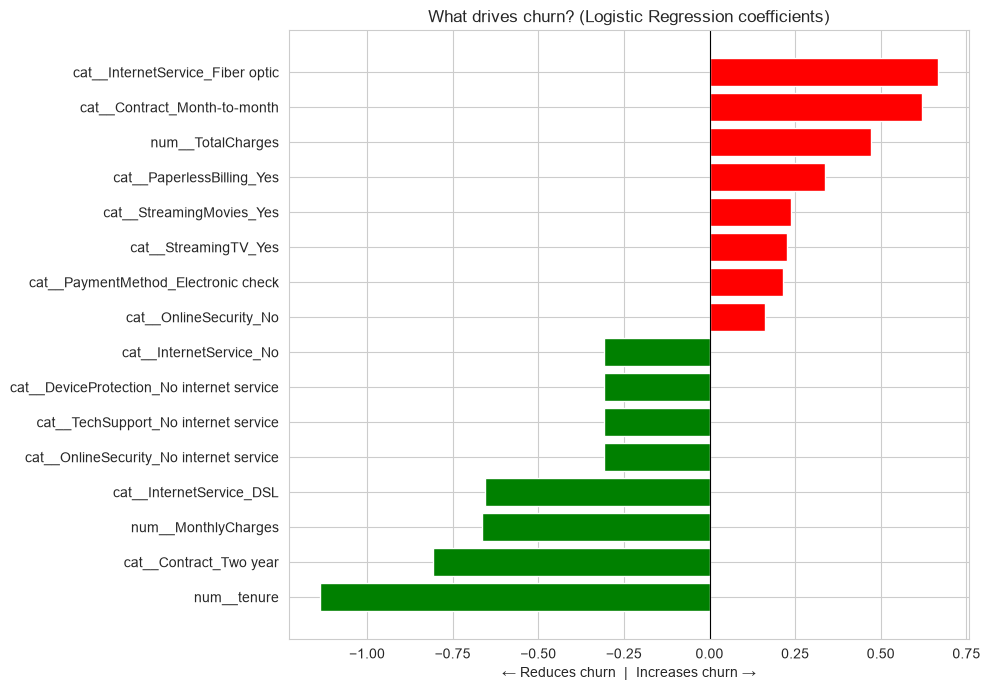

In [29]:
final_model = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
final_model.fit(X_train_prep, y_train)

feature_names = preprocessor.get_feature_names_out()
coefs = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': final_model.coef_[0]
}).sort_values('Coefficient')

top = pd.concat([coefs.head(8), coefs.tail(8)])

plt.figure(figsize=(10, 7))
colors = ['green' if c < 0 else 'red' for c in top['Coefficient']]
plt.barh(top['Feature'], top['Coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('What drives churn? (Logistic Regression coefficients)')
plt.xlabel('← Reduces churn  |  Increases churn →')
plt.tight_layout()
plt.show()